# Evaluating Classification

## Which messages should the filter hide?

A spam filter can hide a legitimate message or leave spam in the inbox. These are different mistakes. Spam is the positive class. As in the binary example, the input features are promotional phrase count and link count. This separate synthetic dataset has fewer spam messages than legitimate messages.

A logistic model learns $z=b+w_1x_1+w_2x_2$ from training messages and estimates $p=\sigma(z)$. Its fitted coefficients stay fixed while the threshold changes. A validation message is classified as spam when $p\ge\tau$.

<img src="https://raw.githubusercontent.com/sonamu-jun/introduction-to-ai-convergence/main/07-1_Classification/assets/05_confusion_matrix.png" alt="Rows show actual message classes and columns show predicted actions. Counts include correctly kept messages, false alarms, missed spam and caught spam at threshold 0.50." width="640" style="max-width:100%;height:auto;">

Rows are actual classes; columns are predicted actions. True positives (TP) are spam caught, and false positives (FP) are legitimate messages hidden. False negatives (FN) are spam missed, and true negatives (TN) are legitimate messages kept.


## Measuring different mistakes

Accuracy counts correct predictions among all $N=TP+TN+FP+FN$ messages:

$$
\mathrm{Accuracy}=\frac{TP+TN}{N}.
$$

When spam is rare, keeping every message can give high accuracy while catching no spam. Precision and recall focus on the positive class:

$$
\mathrm{Precision}=\frac{TP}{TP+FP}, \qquad
\mathrm{Recall}=\frac{TP}{TP+FN}.
$$

Precision measures the fraction of filtered messages that really are spam. Recall measures the fraction of all actual spam that was caught. Their denominators describe different groups.

F1 combines precision and recall through their harmonic mean. Its equivalent count form is

$$
F_1=\frac{2TP}{2TP+FP+FN}.
$$

Both false alarms and missed spam reduce F1. True negatives do not enter it, and it does not express every cost of a filtering mistake.

Raising the threshold filters fewer messages, so false alarms and recall cannot increase. Precision need not increase at every step on a finite dataset. The matrix and all four metrics use the same validation predictions. `Best F1` selects among nineteen fixed thresholds from 0.05 to 0.95, preferring the lower value on a tie; it does not refit the model.


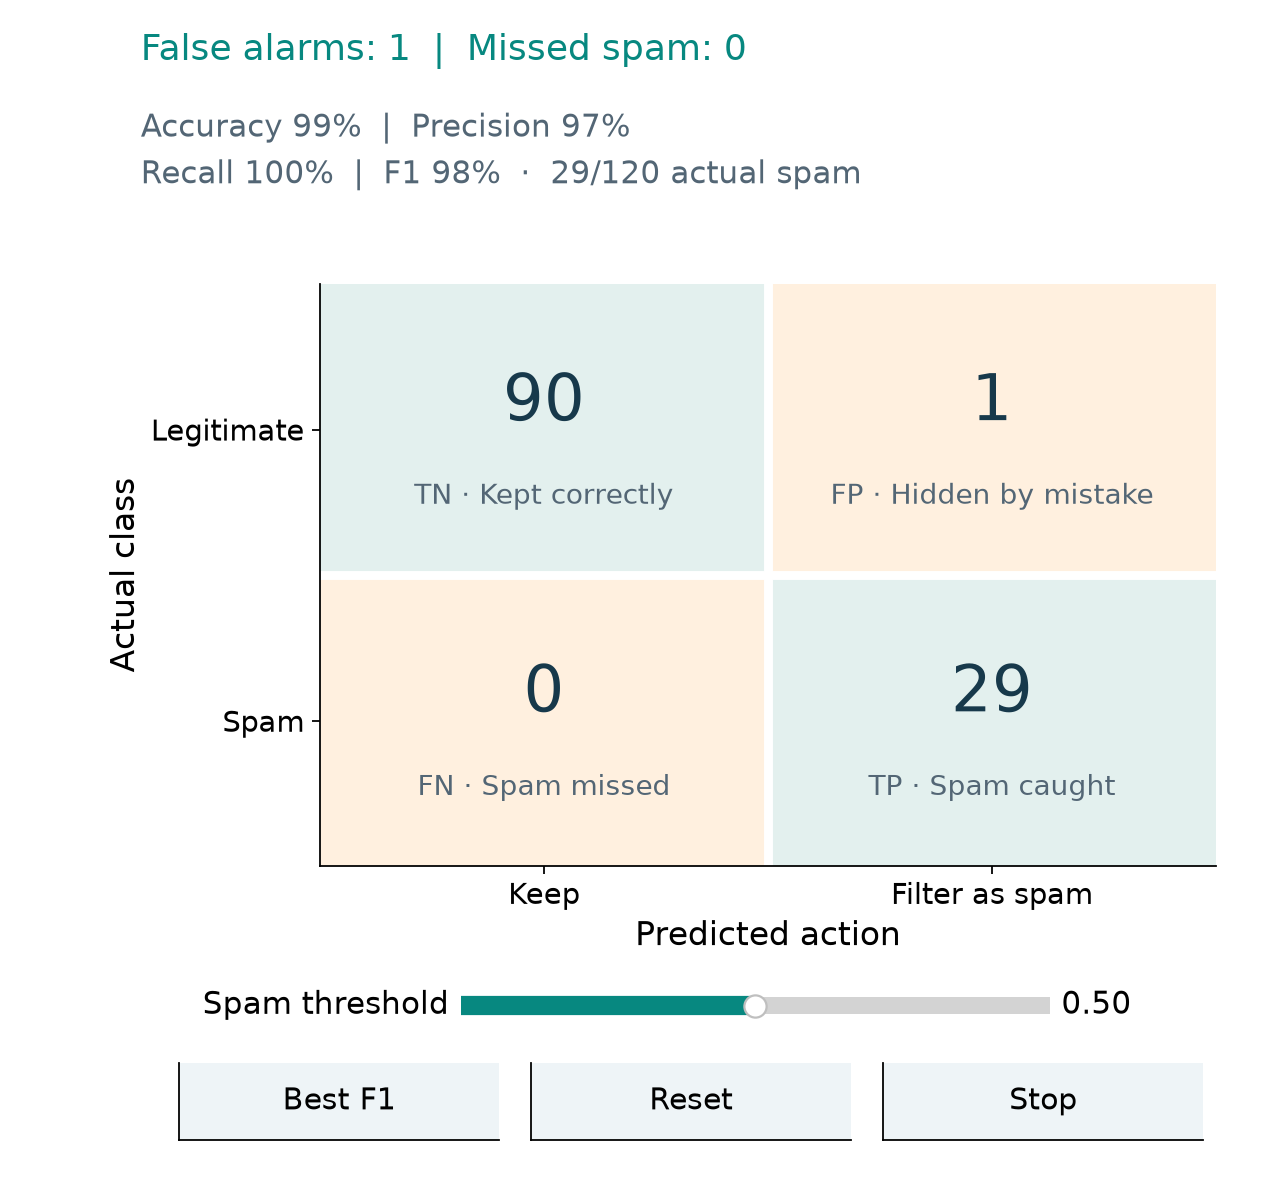

In [1]:
import os
import sys
import io
import numpy as np
import matplotlib

CLASSIFICATION_STATIC = os.environ.get("CLASSIFICATION_STATIC") == "1"
CLASSIFICATION_BROWSER = sys.platform == "emscripten"
if not CLASSIFICATION_STATIC and not CLASSIFICATION_BROWSER:
    from IPython import get_ipython
    shell = get_ipython()
    if shell is not None and getattr(shell, "kernel", None) is not None:
        shell.run_line_magic("matplotlib", "widget")

import matplotlib.pyplot as plt
from matplotlib.widgets import Slider, Button
from matplotlib.colors import ListedColormap
from IPython.display import Image, display
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

plt.rcParams.update({
    "font.size": 15, "axes.labelsize": 15,
    "xtick.labelsize": 13, "ytick.labelsize": 13, "legend.fontsize": 12,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": .16, "lines.linewidth": 2.5,
    "axes.unicode_minus": False, "figure.facecolor": "white",
})
BLUE, TEAL, ORANGE, PURPLE = "#3268a8", "#078880", "#d87522", "#8251ac"


def sigmoid(score):
    score = np.clip(np.asarray(score, dtype=float), -500, 500)
    return 1 / (1 + np.exp(-score))


def softmax(scores):
    scores = np.asarray(scores, dtype=float)
    weights = np.exp(scores - scores.max(axis=-1, keepdims=True))
    return weights / weights.sum(axis=-1, keepdims=True)


def binary_loss(labels, scores):
    # The logaddexp form avoids taking log(0) at extreme scores.
    return float(np.mean(np.logaddexp(0, scores) - labels * scores))


def classification_metrics(observed, predicted):
    observed, predicted = np.asarray(observed), np.asarray(predicted)
    tp = int(np.sum((observed == 1) & (predicted == 1)))
    tn = int(np.sum((observed == 0) & (predicted == 0)))
    fp = int(np.sum((observed == 0) & (predicted == 1)))
    fn = int(np.sum((observed == 1) & (predicted == 0)))
    return {"TP": tp, "TN": tn, "FP": fp, "FN": fn,
            "accuracy": (tp + tn) / len(observed),
            "precision": tp / (tp + fp) if tp + fp else np.nan,
            "recall": tp / (tp + fn) if tp + fn else np.nan,
            "F1": 2 * tp / (2 * tp + fp + fn) if 2 * tp + fp + fn else np.nan}


def percent(value):
    return "undefined" if not np.isfinite(value) else f"{value:.0%}"


# A rerun releases the previous figure and its input callbacks first.
for _previous_view in globals().get("_classification_views", {}).values():
    _previous_view.close()
_classification_views = {}


class ClassificationExplorer:
    """One figure keeps the selected model, predictions and scores together."""

    def __init__(self, name, render, sliders, actions=()):
        self.render = render
        self.slider_specs = sliders
        self.controls, self.buttons, self.state = {}, {}, {}
        self.stopped = False
        self.defaults = {key: initial for key, label, low, high, initial, step, fmt in sliders}
        with plt.ioff():
            height = min(8.0, 6.8 + .58 * len(sliders))
            self.figure = plt.figure(figsize=(8, height), dpi=80)
        self.status = self.figure.text(.11, 1 - .38 / height, "", fontsize=16, color=TEAL)
        self.detail = self.figure.text(.11, 1 - .66 / height, "", va="top", fontsize=14, color="#536675", linespacing=1.5)
        bottom = (1.38 + .58 * len(sliders)) / height
        top = 1 - 1.78 / height
        self.ax = self.figure.add_axes([.14, bottom, .81, top - bottom])
        for i, (key, label, low, high, initial, step, fmt) in enumerate(sliders):
            y = (.98 + .58 * (len(sliders) - i - 1)) / height
            slider = Slider(self.figure.add_axes([.36, y, .46, .22 / height]),
                            label, low, high, valinit=initial, valstep=step,
                            valfmt=fmt, color=TEAL)
            slider.label.set_fontsize(14)
            slider.valtext.set_fontsize(14)
            slider.on_changed(self.update)
            self.controls[key] = slider
        commands = list(actions) + [("Reset", lambda view: view.reset()),
                                    ("Stop", lambda view: view.stop())]
        self.commands = commands
        width = min(.25, .83 / len(commands) - .025)
        for i, (label, callback) in enumerate(commands):
            button = Button(self.figure.add_axes([.14 + i * (width + .025), .25 / height, width, .48 / height]),
                            label, color="#eef4f7", hovercolor="#d7e9e6")
            button.label.set_fontsize(13.5)
            button.on_clicked(lambda event, cb=callback: cb(self) if not self.stopped else None)
            self.buttons[label] = button
        self.figure.canvas.mpl_connect("close_event", lambda event: self.stop())
        _classification_views[name] = self
        self.update()

    def update(self, _=None):
        if self.stopped:
            return
        self.ax.clear()
        self.state = self.render(self, **{key: slider.val for key, slider in self.controls.items()})
        self.figure.canvas.draw_idle()
        self.refresh_local()

    def set_values(self, **values):
        if self.stopped:
            return
        for key, value in values.items():
            slider = self.controls[key]
            events, drawing = slider.eventson, slider.drawon
            slider.eventson = slider.drawon = False
            slider.set_val(value)
            slider.eventson, slider.drawon = events, drawing
        self.update()

    def reset(self):
        self.set_values(**self.defaults)

    def refresh_local(self):
        if not hasattr(self, "local_image"):
            return
        from matplotlib.transforms import Bbox
        width, height = self.figure.get_size_inches()
        # Crop only the embedded Matplotlib controls; native widgets follow the chart.
        lower = max(0, self.ax.get_position().y0 * height - .78)
        buffer = io.BytesIO()
        self.figure.savefig(buffer, format="png", dpi=80, facecolor="white",
                            bbox_inches=Bbox.from_extents(0, lower, width, height))
        self.local_image.value = buffer.getvalue()
        self.syncing_local = True
        for key, control in self.local_controls.items():
            control.value = self.controls[key].val
        self.syncing_local = False

    def start_local(self):
        from ipywidgets import Image as WidgetImage, FloatSlider, IntSlider
        from ipywidgets import Button as WidgetButton, HBox, VBox, Layout
        self.syncing_local = False
        self.local_image = WidgetImage(format="png", layout=Layout(
            width="100%", max_width="640px", height="auto"))
        self.local_controls, self.local_buttons = {}, {}
        for key, label, low, high, initial, step, fmt in self.slider_specs:
            slider_type = IntSlider if fmt == "%0.0f" and step == 1 else FloatSlider
            control = slider_type(value=initial, min=low, max=high, step=step,
                                  description=label, readout_format=fmt.replace("%0", ""),
                                  continuous_update=True,
                                  style={"description_width": "120px"},
                                  layout=Layout(width="100%", max_width="640px"))
            def changed(change, key=key):
                if not self.syncing_local and not self.stopped:
                    self.controls[key].set_val(change["new"])
            control.observe(changed, names="value")
            self.local_controls[key] = control
        for label, callback in self.commands:
            button = WidgetButton(description=label, layout=Layout(
                flex="1 1 0", min_width="120px", height="34px", margin="2px"))
            button.on_click(lambda _, cb=callback: cb(self) if not self.stopped else None)
            self.local_buttons[label] = button
        row = HBox(list(self.local_buttons.values()), layout=Layout(width="100%", flex_flow="row wrap"))
        self.local_row = row
        self.local_output = VBox([self.local_image, *self.local_controls.values(), row],
                                layout=Layout(width="100%", max_width="640px"))
        self.refresh_local()
        display(self.local_output)

    def start(self):
        if CLASSIFICATION_STATIC:
            buffer = io.BytesIO()
            self.figure.savefig(buffer, format="png", dpi=160, facecolor="white")
            display(Image(data=buffer.getvalue(), width=640,
                          alt=self.status.get_text() + ". " + self.detail.get_text()))
            plt.close(self.figure)
        elif CLASSIFICATION_BROWSER:
            # JSPCV sends mouse events after this cell has returned.
            plt.show(block=False)
        elif hasattr(self.figure.canvas, "toolbar_visible"):
            # The ipympl figure supplies a responsive chart with native widget controls.
            self.start_local()
        else:
            plt.show(block=False)

    def stop(self):
        if self.stopped:
            return
        self.stopped = True
        for control in list(self.controls.values()) + list(self.buttons.values()):
            control.set_active(False)
        for control in [*getattr(self, "local_controls", {}).values(),
                        *getattr(self, "local_buttons", {}).values()]:
            control.disabled = True
        if hasattr(self, "local_buttons"):
            self.local_buttons["Stop"].description = "Stopped"
        self.buttons["Stop"].label.set_text("Stopped")
        self.figure.canvas.draw_idle()

    def close(self):
        self.stop()
        for control in list(self.controls.values()) + list(self.buttons.values()):
            control.disconnect_events()
        plt.close(self.figure)
        if hasattr(self, "local_output"):
            self.local_output.close()
            self.local_image.close()
            self.local_row.close()
            for control in [*self.local_controls.values(), *self.local_buttons.values()]:
                control.close()



def make_messages(seed, count=240, spam_fraction=.35):
    """Synthetic labels and counts; no real messages or URLs are collected."""
    rng = np.random.default_rng(seed)
    labels = np.zeros(count, dtype=int)
    labels[:round(count * spam_fraction)] = 1
    rng.shuffle(labels)
    phrases = rng.binomial(10, np.where(labels == 1, .53, .13))
    links = rng.binomial(4, np.where(labels == 1, .57, .13))
    return np.column_stack([phrases, links]), labels


def make_fruit(seed):
    """Synthetic fruit measurements: hue in degrees and length / width."""
    rng = np.random.default_rng(seed)
    labels = np.repeat(np.arange(3), 60)
    centers = np.array([[8, 1.15], [30, 1.05], [53, 2.8]])
    spreads = np.array([[8, .18], [7, .16], [7, .5]])
    values = centers[labels] + rng.normal(size=(len(labels), 2)) * spreads[labels]
    return np.clip(values, [0, .7], [70, 4.2]), labels

messages, spam = make_messages(73, count=360, spam_fraction=.24)
train_id, validation_id = train_test_split(np.arange(len(spam)), test_size=1/3,
                                         stratify=spam, random_state=73)
feature_mean, feature_scale = messages[train_id].mean(axis=0), messages[train_id].std(axis=0)


def message_features(values):
    values = np.atleast_2d(values)
    return np.column_stack([np.ones(len(values)), (values - feature_mean) / feature_scale])


train_features = message_features(messages[train_id])
coefficients = np.zeros(3)
for iteration in range(1200):
    probability = sigmoid(train_features @ coefficients)
    coefficients -= .15 * train_features.T @ (probability - spam[train_id]) / len(train_id)
validation_probability = sigmoid(message_features(messages[validation_id]) @ coefficients)
candidate_thresholds = np.linspace(.05, .95, 19)
candidate_f1 = [classification_metrics(spam[validation_id], validation_probability >= threshold)["F1"]
                for threshold in candidate_thresholds]
# Ties favor the first (lower) threshold in the fixed list.
best_threshold = float(candidate_thresholds[int(np.nanargmax(candidate_f1))])


def render_messages(view, threshold):
    predicted = (validation_probability >= threshold).astype(int)
    result = classification_metrics(spam[validation_id], predicted)
    matrix = np.array([[result["TN"], result["FP"]], [result["FN"], result["TP"]]])
    ax = view.ax
    position = ax.get_position()
    ax.set_position([.25, position.y0, .70, position.height])
    ax.grid(False)
    ax.imshow([[0, 1], [1, 0]], cmap=ListedColormap(["#e3f0ee", "#fff0df"]), vmin=0, vmax=1,
              extent=(-.5, 1.5, 1.5, -.5), aspect="auto")
    descriptions = [["TN · Kept correctly", "FP · Hidden by mistake"],
                    ["FN · Spam missed", "TP · Spam caught"]]
    for row in range(2):
        for col in range(2):
            ax.text(col, row-.09, str(matrix[row, col]), ha="center", va="center",
                    fontsize=29, color="#17394b")
            ax.text(col, row+.23, descriptions[row][col], ha="center", va="center",
                    fontsize=12.5, color="#536675")
    ax.axhline(.5, color="white", linewidth=4)
    ax.axvline(.5, color="white", linewidth=4)
    ax.set(xticks=[0, 1], xticklabels=["Keep", "Filter as spam"],
           yticks=[0, 1], yticklabels=["Legitimate", "Spam"],
           xlabel="Predicted action", ylabel="Actual class")
    total, positives = len(validation_id), int(spam[validation_id].sum())
    view.status.set_text(f"False alarms: {result['FP']}  |  Missed spam: {result['FN']}")
    view.detail.set_text(f"Accuracy {percent(result['accuracy'])}  |  Precision {percent(result['precision'])}\n"
                         f"Recall {percent(result['recall'])}  |  F1 {percent(result['F1'])}  ·  {positives}/{total} actual spam")
    return {"prediction": predicted, "metrics": result, "matrix": matrix,
            "probability": validation_probability.copy()}


spam_demo = ClassificationExplorer("spam", render_messages, [
    ("threshold", "Spam threshold", 0, 1, .5, .01, "%0.2f"),
], actions=[("Best F1", lambda view: view.set_values(threshold=best_threshold))])
spam_demo.start()


## Undefined precision and changing data

At threshold one, this model filters no messages. Then $TP+FP=0$, so precision is undefined. Recall and F1 are zero because this dataset contains actual spam and none is caught. At threshold zero, every message is filtered: recall is one, but legitimate messages are also hidden.

Cross-entropy evaluates probabilities; accuracy, precision, recall, and F1 here evaluate thresholded decisions. A different threshold can change these four metrics without changing probabilities or cross-entropy.

A useful threshold depends on the cost of each mistake. New message patterns or a different spam proportion can change performance. Choosing a threshold on validation data requires a separate test set for final evaluation. In multiclass classification, per-class metrics or a macro average can reveal errors hidden by overall accuracy.
